# Phần 1.2 — TMDb: kinh doanh và phát hành phim

Notebook này dùng **TMDb API** (chi tiết phim + ngày phát hành theo từng nước), ghép với IMDb để lấy thể loại và số vote. Dữ liệu chuẩn bị bởi `src/06_fetch_tmdb.py` → `src/07_tmdb_to_table.py`: ~138k phim, gồm **mọi phim IMDb có ≥ 1.000 vote** (không giới hạn ở phim có trên torrent).

Lưu ý dữ liệu: TMDb ghi ngân sách/doanh thu = 0 khi không rõ → coi là thiếu; chỉ ~9.300 phim có đủ cả hai (chủ yếu phim Mỹ/phim lớn). Tiền là **USD danh nghĩa**, chưa điều chỉnh lạm phát. Biểu đồ lưu vào `plots/2_tmdb/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import squarify
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "2_tmdb"
SRC = "Nguồn: TMDb API (2026), IMDb."

mv = duckdb.sql(f"""
    SELECT t.*, i.genres, i.start_year, i.num_votes, i.avg_rating
    FROM read_parquet('{(V.DC / "tmdb_movies.parquet").as_posix()}') t
    JOIN read_parquet('{(V.DC / "imdb_movies_all.parquet").as_posix()}') i ON i.tconst = t.imdb_id
    WHERE t.tmdb_found AND NOT i.is_adult
""").df()
rd = duckdb.sql(f"SELECT * FROM read_parquet('{(V.DC / 'tmdb_release_dates.parquet').as_posix()}')").df()
fin = mv[(mv["budget"] >= 1e6) & (mv["revenue"] >= 1e4) & mv["release_date"].dt.year.between(1980, 2024)].copy()
fin["roi"] = fin["revenue"] / fin["budget"]
money = FuncFormatter(lambda x, _: "$0" if x == 0 else (f"${x / 1e9:.0f} tỷ" if x >= 1e9 else
                      (f"${x / 1e6:.0f} tr" if x >= 1e6 else f"${x / 1e3:.0f}k")))
print(f"{len(mv):,} phim có trên TMDb; {len(fin):,} phim có cả ngân sách (≥ $1 triệu) và doanh thu, 1980–2024")

135,585 phim có trên TMDb; 9,324 phim có cả ngân sách (≥ $1 triệu) và doanh thu, 1980–2024


## 1. Phim có thu hồi được vốn không?

  wrote plots\2_tmdb\01_budget_vs_revenue.png


WindowsPath('D:/dulieulon/plots/2_tmdb/01_budget_vs_revenue.png')

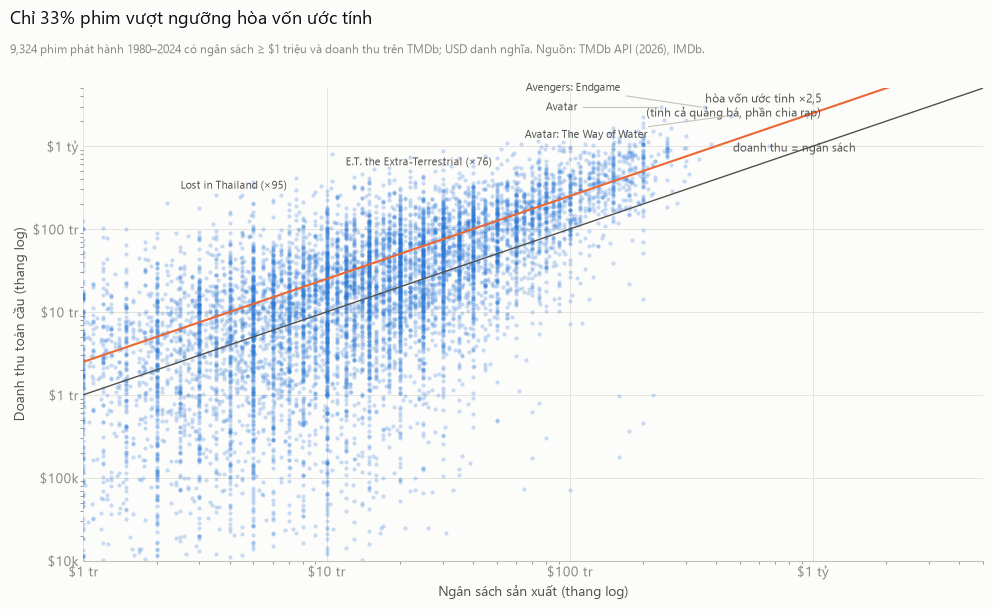

In [3]:
fig, ax = plt.subplots(figsize=(10, 6.2))
V.style_axes(ax, grid="both")
ax.scatter(fin["budget"], fin["revenue"], s=9, color=V.BLUE, alpha=0.25, linewidths=0)
lims = np.array([1e6, 5e9])
ax.plot(lims, lims, color=V.INK2, linewidth=1)
ax.plot(lims, lims * 2.5, color=V.ORANGE, linewidth=1.5)
ax.annotate("doanh thu = ngân sách", xy=(1.5e9, 1.5e9), xytext=(0, -8), textcoords="offset points",
            ha="right", va="top", color=V.INK2, fontsize=8.5)
ax.annotate("hòa vốn ước tính ×2,5\n(tính cả quảng bá, phần chia rạp)", xy=(1.2e9, 3e9), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center", color=V.INK2, fontsize=8.5)
profitable = (fin["roi"] >= 2.5).mean()
# Chỉ ghi tên vài phim tiêu biểu, đặt so le để không chồng nhau
for (_, r), dy in zip(fin.nlargest(3, "revenue").iterrows(), (14, 0, -14)):
    ax.annotate(r["tmdb_title"], xy=(r["budget"], r["revenue"]), xytext=(-60, dy),
                textcoords="offset points", ha="right", va="center", color=V.INK2, fontsize=8,
                arrowprops=dict(arrowstyle="-", color=V.AXIS, linewidth=0.8))
for (_, r), dy in zip(fin[fin["budget"].between(2e6, 2e7)].nlargest(2, "roi").iterrows(), (10, -8)):
    ax.annotate(f"{r['tmdb_title']} (×{r['roi']:.0f})", xy=(r["budget"], r["revenue"]), xytext=(10, dy),
                textcoords="offset points", color=V.INK2, fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*lims)
ax.set_ylim(1e4, 5e9)
ax.xaxis.set_major_formatter(money)
ax.yaxis.set_major_formatter(money)
ax.set_xlabel("Ngân sách sản xuất (thang log)")
ax.set_ylabel("Doanh thu toàn cầu (thang log)")
V.titles(fig, f"Chỉ {profitable:.0%} phim vượt ngưỡng hòa vốn ước tính",
         f"{len(fin):,} phim phát hành 1980–2024 có ngân sách ≥ $1 triệu và doanh thu trên TMDb; USD danh nghĩa. {SRC}")
V.save(fig, FOLDER, "01_budget_vs_revenue")

**Nhận xét.** Doanh thu tăng gần tỷ lệ với ngân sách, nhưng phân tán rất lớn (trục log: mỗi vạch = ×10). Chỉ **~33% phim vượt ngưỡng hòa vốn ước tính ×2,5** (ngân sách sản xuất chưa gồm quảng bá; rạp giữ ~50% doanh thu vé). Các "cú hit" ngân sách thấp (vd. *Lost in Thailand* ×95, *E.T.* ×76) cho thấy lợi nhuận cực lớn đến từ phim rẻ, không phải bom tấn. Thiên lệch: phim thất bại thường không công bố doanh thu → tỷ lệ thật có thể còn thấp hơn.

## 2. Thể loại nào sinh lời nhất?

  wrote plots\2_tmdb\02_roi_by_genre.png


WindowsPath('D:/dulieulon/plots/2_tmdb/02_roi_by_genre.png')

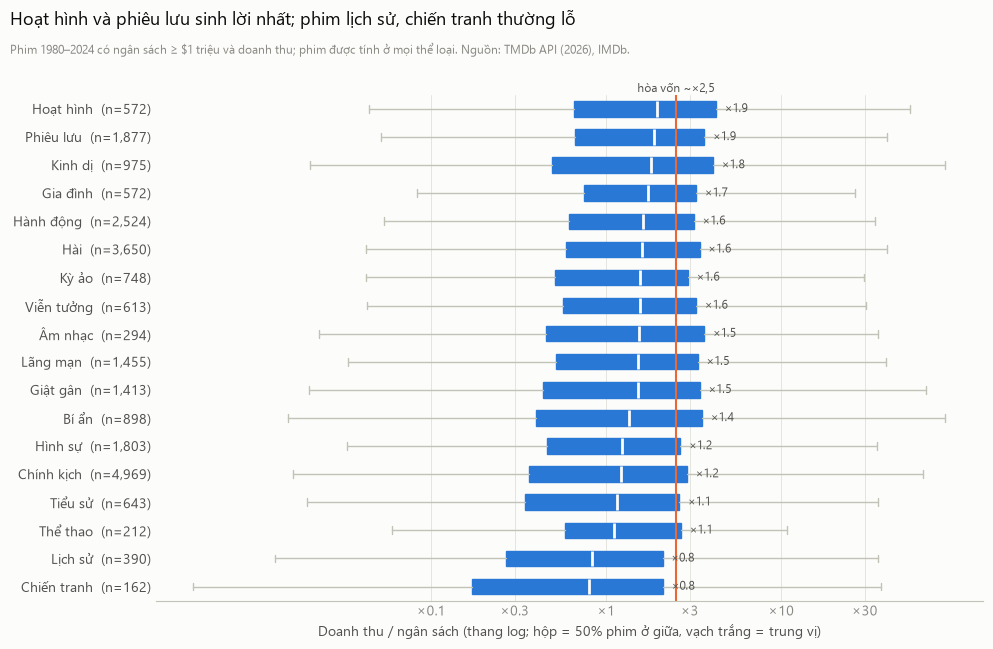

In [4]:
g = fin.assign(genre=fin["genres"].str.split(",")).explode("genre").dropna(subset=["genre"])
cnt = g["genre"].value_counts()
g = g[g["genre"].isin(cnt[cnt >= 150].index)]
order = g.groupby("genre")["roi"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6.6))
V.style_axes(ax, grid="x")
data = [np.log10(g.loc[g["genre"] == x, "roi"].values) for x in order]
ax.boxplot(data, orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
           medianprops=dict(color=V.SURFACE, linewidth=2), whiskerprops=dict(color=V.AXIS),
           capprops=dict(color=V.AXIS), boxprops=dict(facecolor=V.BLUE, edgecolor=V.BLUE))
ax.axvline(np.log10(2.5), color=V.ORANGE, linewidth=1.5)
ax.annotate("hòa vốn ~×2,5", xy=(np.log10(2.5), len(order) + 0.6), ha="center", color=V.INK2, fontsize=8.5,
            annotation_clip=False)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{V.GENRE_VI.get(x, x)}  (n={cnt[x]:,})" for x in order], color=V.INK2)
for i, x in enumerate(order, 1):
    m = np.median(g.loc[g["genre"] == x, "roi"])
    ax.annotate(f"×{m:.1f}", xy=(np.percentile(data[i - 1], 75), i), xytext=(6, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=8.5)
ticks = [0.1, 0.3, 1, 3, 10, 30]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels([f"×{t:g}" for t in ticks])
ax.set_xlabel("Doanh thu / ngân sách (thang log; hộp = 50% phim ở giữa, vạch trắng = trung vị)")
V.titles(fig, "Hoạt hình và phiêu lưu sinh lời nhất; phim lịch sử, chiến tranh thường lỗ",
         f"Phim 1980–2024 có ngân sách ≥ $1 triệu và doanh thu; phim được tính ở mọi thể loại. {SRC}")
V.save(fig, FOLDER, "02_roi_by_genre")

**Nhận xét.** **Trung vị của mọi thể loại đều dưới ngưỡng hòa vốn ×2,5** — phần lớn phim không có lãi. Hoạt hình và phiêu lưu cao nhất (×1,9), kinh dị ×1,8 nhưng có **đuôi trên dài nhất** (phim kinh dị rẻ đôi khi lãi cực lớn). Lịch sử và chiến tranh thấp nhất (×0,8): ngân sách dựng cảnh lớn, khán giả hẹp.

## 3. Bom tấn ra rạp vào tháng nào?

  wrote plots\2_tmdb\03_release_month_polar.png


WindowsPath('D:/dulieulon/plots/2_tmdb/03_release_month_polar.png')

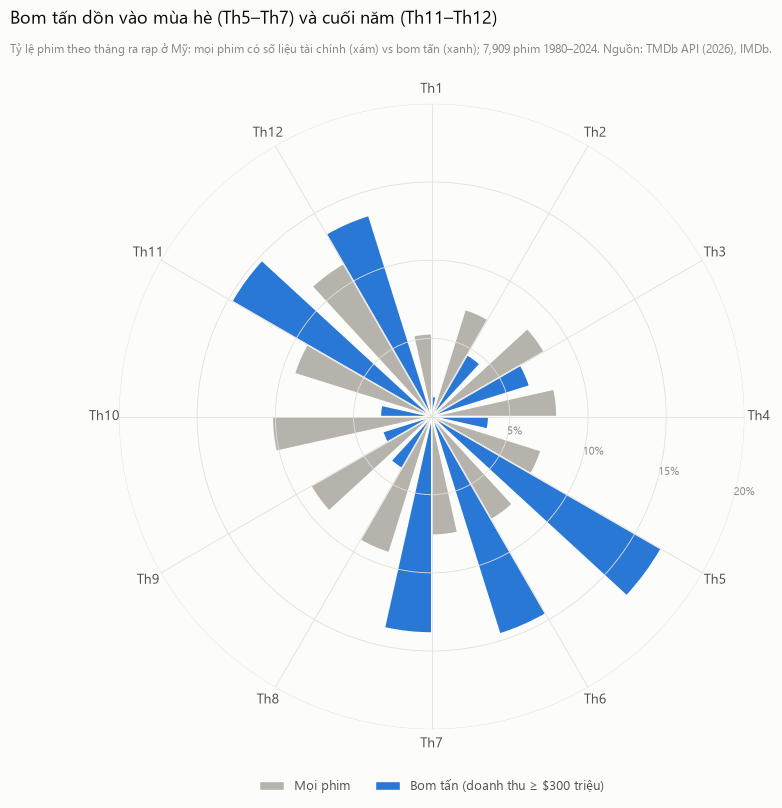

In [5]:
us = (rd[(rd["country"] == "US") & rd["type"].isin([2, 3])]
      .groupby("imdb_id")["release_date"].min().rename("us_release"))
m3 = fin.join(us, on="imdb_id").dropna(subset=["us_release"])
m3["month"] = m3["us_release"].dt.month
all_m = m3["month"].value_counts(normalize=True).sort_index()
big_m = m3[m3["revenue"] >= 3e8]["month"].value_counts(normalize=True).reindex(range(1, 13), fill_value=0)
theta = np.linspace(0, 2 * np.pi, 12, endpoint=False)
width = 2 * np.pi / 12 * 0.42
fig = plt.figure(figsize=(8.6, 8.2))
ax = fig.add_subplot(projection="polar")
ax.set_facecolor(V.SURFACE)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.bar(theta - width / 2, all_m.values, width=width, color=V.OTHER, edgecolor=V.SURFACE, label="Mọi phim")
ax.bar(theta + width / 2, big_m.values, width=width, color=V.BLUE, edgecolor=V.SURFACE,
       label="Bom tấn (doanh thu ≥ $300 triệu)")
ax.set_xticks(theta)
ax.set_xticklabels([f"Th{m}" for m in range(1, 13)], color=V.INK2)
ax.set_yticks([0.05, 0.10, 0.15, 0.20])
ax.set_yticklabels(["5%", "10%", "15%", "20%"], color=V.MUTED, fontsize=8)
ax.set_rlabel_position(105)
ax.grid(color=V.GRID, linewidth=0.6)
ax.spines["polar"].set_visible(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2)
V.titles(fig, "Bom tấn dồn vào mùa hè (Th5–Th7) và cuối năm (Th11–Th12)",
         f"Tỷ lệ phim theo tháng ra rạp ở Mỹ: mọi phim có số liệu tài chính (xám) vs bom tấn (xanh); "
         f"{len(m3):,} phim 1980–2024. {SRC}")
V.save(fig, FOLDER, "03_release_month_polar")

**Nhận xét.** Phim nói chung ra rải rác quanh năm (mùa thu nhiều phim nhỏ), nhưng **bom tấn (≥ $300 triệu) dồn vào mùa hè (Th5–Th7) và mùa lễ cuối năm (Th11–Th12)** — đúng hai mùa nghỉ học/nghỉ lễ ở Mỹ. Tháng 1–4 và 8–10 gần như vắng bom tấn.

## 4. Phim lên bản online sau bao lâu?

  wrote plots\2_tmdb\04_theatrical_window.png


WindowsPath('D:/dulieulon/plots/2_tmdb/04_theatrical_window.png')

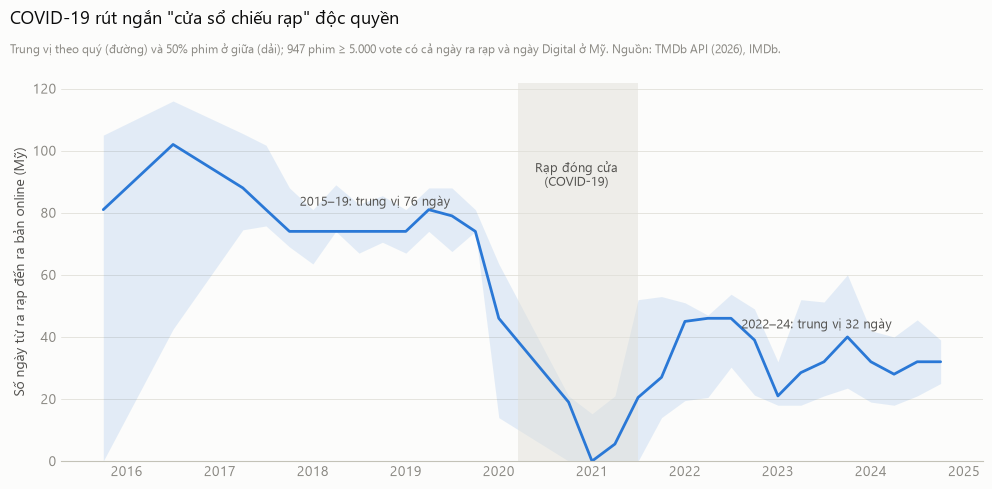

In [6]:
usd = rd[rd["country"] == "US"].pivot_table(index="imdb_id", columns="type", values="release_date", aggfunc="min")
win = usd.dropna(subset=[3, 4]).copy()
win["gap"] = (win[4] - win[3]).dt.days
win = win[win["gap"].between(0, 365) & win[3].dt.year.between(2012, 2024)]
win = win.join(mv.set_index("imdb_id")["num_votes"]).query("num_votes >= 5000")
q = win.groupby(win[3].dt.to_period("Q"))["gap"].describe(percentiles=[0.25, 0.5, 0.75])
q = q[q["count"] >= 10]
x = q.index.to_timestamp()
fig, ax = plt.subplots(figsize=(10, 5))
V.style_axes(ax)
ax.fill_between(x, q["25%"], q["75%"], color=V.BLUE, alpha=0.12, linewidth=0)
ax.plot(x, q["50%"], color=V.BLUE)
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2021-06-30"), color=V.GRID, alpha=0.5, linewidth=0)
ax.annotate("Rạp đóng cửa\n(COVID-19)", xy=(pd.Timestamp("2020-11-01"), q["50%"].max() * 0.95),
            ha="center", va="top", color=V.INK2, fontsize=9)
pre = win[win[3].dt.year.between(2015, 2019)]["gap"].median()
post = win[win[3].dt.year.between(2022, 2024)]["gap"].median()
ax.annotate(f"2015–19: trung vị {pre:.0f} ngày", xy=(pd.Timestamp("2018-09-01"), pre), xytext=(0, 14),
            textcoords="offset points", ha="center", color=V.INK2, fontsize=9)
ax.annotate(f"2022–24: trung vị {post:.0f} ngày", xy=(pd.Timestamp("2023-06-01"), post), xytext=(0, 24),
            textcoords="offset points", ha="center", color=V.INK2, fontsize=9)
ax.set_ylim(0)
ax.set_ylabel("Số ngày từ ra rạp đến ra bản online (Mỹ)")
V.titles(fig, "COVID-19 rút ngắn \"cửa sổ chiếu rạp\" độc quyền",
         f"Trung vị theo quý (đường) và 50% phim ở giữa (dải); {len(win):,} phim ≥ 5.000 vote có cả ngày ra rạp "
         f"và ngày Digital ở Mỹ. {SRC}")
V.save(fig, FOLDER, "04_theatrical_window")

**Nhận xét.** Trước COVID, phim ở rạp độc quyền **~76 ngày** (trung vị 2015–19) mới lên bản online. Khi rạp đóng cửa (2020–21), nhiều phim phát hành online cùng ngày hoặc ngay sau đó. Sau khi rạp mở lại, cửa sổ **không quay về mức cũ mà ổn định ở ~32 ngày** — COVID đã thay đổi vĩnh viễn mô hình phát hành.

## 5. Phim được sản xuất ở đâu?

  wrote plots\2_tmdb\05_origin_country_treemap.png


WindowsPath('D:/dulieulon/plots/2_tmdb/05_origin_country_treemap.png')

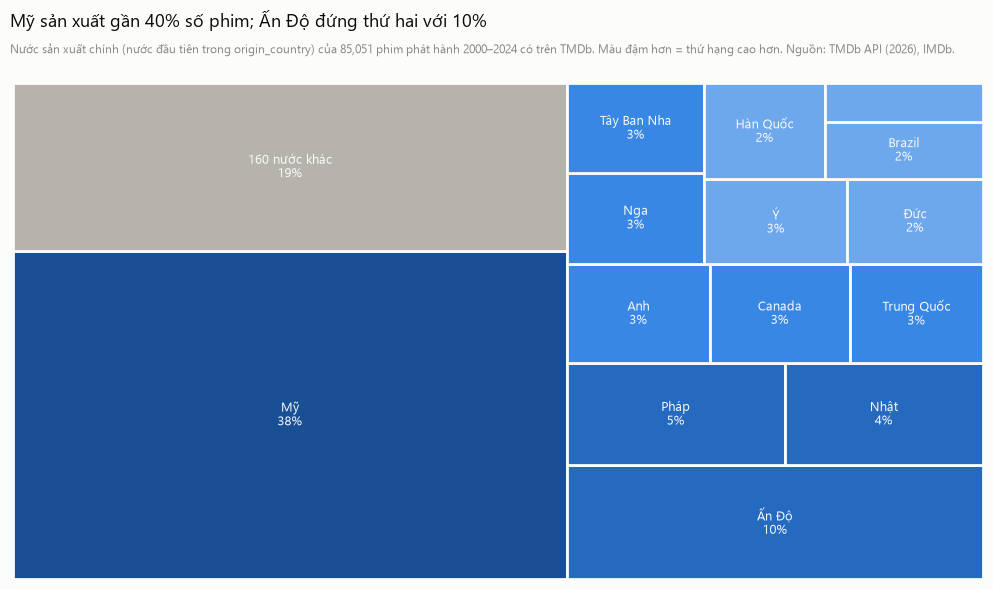

In [7]:
c = mv[mv["release_date"].dt.year.between(2000, 2024)].copy()
c = c.assign(country=c["origin_country"].fillna("").str.split(",").str[0]).query("country != ''")
counts = c["country"].value_counts()
top = counts.head(14)
rest = counts.iloc[14:].sum()
NAMES = V.COUNTRY_VI
# squarify cần kích thước giảm dần -> xếp cả ô "nước khác" vào đúng thứ tự
rank_color = lambda i: V.SEQ_STEPS[5] if i == 0 else V.SEQ_STEPS[4] if i < 4 else V.SEQ_STEPS[3] if i < 9 else V.SEQ_STEPS[2]
tiles = [(NAMES.get(k, k), v, rank_color(i)) for i, (k, v) in enumerate(top.items())]
tiles = sorted(tiles + [(f"{len(counts) - 14} nước khác", rest, V.OTHER)], key=lambda t: -t[1])
sizes = [t[1] for t in tiles]
labels = [f"{t[0]}\n{t[1] / counts.sum():.0%}" if t[1] / counts.sum() >= 0.015 else "" for t in tiles]
colors = [t[2] for t in tiles]
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis("off")
squarify.plot(sizes=sizes, label=labels, color=colors, ax=ax, pad=False, bar_kwargs=dict(edgecolor=V.SURFACE, linewidth=2),
              text_kwargs=dict(color=V.SURFACE, fontsize=9))
V.titles(fig, "Mỹ sản xuất gần 40% số phim; Ấn Độ đứng thứ hai với 10%",
         f"Nước sản xuất chính (nước đầu tiên trong origin_country) của {counts.sum():,} phim phát hành 2000–2024 có trên TMDb. "
         f"Màu đậm hơn = thứ hạng cao hơn. {SRC}")
V.save(fig, FOLDER, "05_origin_country_treemap")

**Nhận xét.** Mỹ chiếm **~38%** số phim (2000–2024) trên TMDb, **Ấn Độ ~10%** đứng thứ hai, rồi Pháp, Nhật. Lưu ý thiên lệch: TMDb do cộng đồng (chủ yếu phương Tây) đóng góp nên phim Mỹ được ghi nhận đầy đủ hơn — theo số liệu chính thức, Ấn Độ thực tế sản xuất nhiều phim hơn Mỹ mỗi năm.

## 6. Phim nhượng quyền chiếm bao nhiêu doanh thu?

  wrote plots\2_tmdb\06_franchise_share.png


WindowsPath('D:/dulieulon/plots/2_tmdb/06_franchise_share.png')

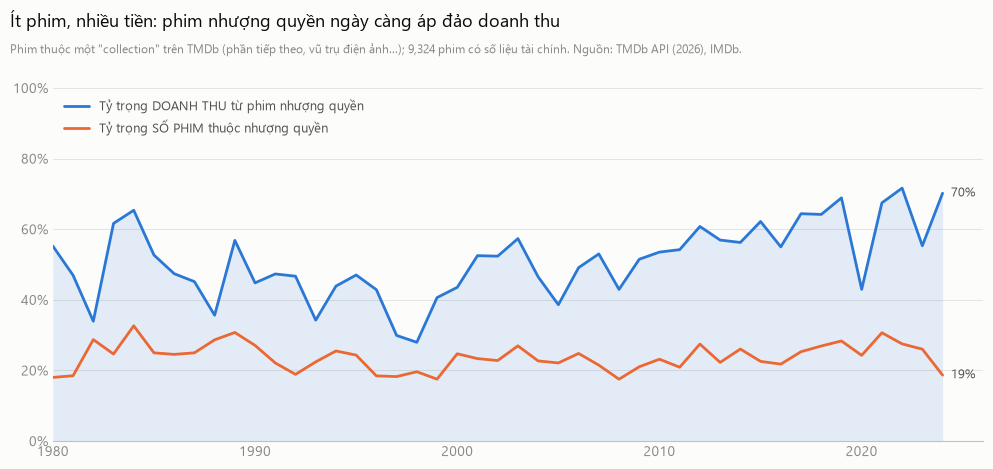

In [8]:
yr = fin.groupby([fin["release_date"].dt.year, "in_collection"])["revenue"].sum().unstack(fill_value=0)
share = yr[True] / yr.sum(axis=1)
nshare = fin.groupby(fin["release_date"].dt.year)["in_collection"].mean()
fig, ax = plt.subplots(figsize=(10, 4.8))
V.style_axes(ax)
ax.fill_between(share.index, share.values, color=V.BLUE, alpha=0.12, linewidth=0)
ax.plot(share.index, share.values, color=V.BLUE, label="Tỷ trọng DOANH THU từ phim nhượng quyền")
ax.plot(nshare.index, nshare.values, color=V.ORANGE, label="Tỷ trọng SỐ PHIM thuộc nhượng quyền")
ax.annotate(f"{share.iloc[-1]:.0%}", xy=(share.index[-1], share.iloc[-1]), xytext=(6, 0), textcoords="offset points",
            va="center", color=V.INK2, fontsize=9)
ax.annotate(f"{nshare.iloc[-1]:.0%}", xy=(nshare.index[-1], nshare.iloc[-1]), xytext=(6, 0), textcoords="offset points",
            va="center", color=V.INK2, fontsize=9)
ax.set_ylim(0, 1)
ax.set_xlim(1980, 2026)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper left")
V.titles(fig, "Ít phim, nhiều tiền: phim nhượng quyền ngày càng áp đảo doanh thu",
         f"Phim thuộc một \"collection\" trên TMDb (phần tiếp theo, vũ trụ điện ảnh…); {len(fin):,} phim có số liệu tài chính. {SRC}")
V.save(fig, FOLDER, "06_franchise_share")

**Nhận xét.** Phim thuộc loạt (phần tiếp theo, vũ trụ điện ảnh) chỉ chiếm **~20–30% số phim** nhưng **50–70% doanh thu**, và tỷ trọng doanh thu tăng rõ từ thập niên 2000 (kỷ nguyên Marvel, Harry Potter…). Năm 2020 giảm vì bom tấn dời lịch do COVID.

## 7. Hãng nào đứng sau doanh thu lớn nhất?

  wrote plots\2_tmdb\07_top_companies.png


WindowsPath('D:/dulieulon/plots/2_tmdb/07_top_companies.png')

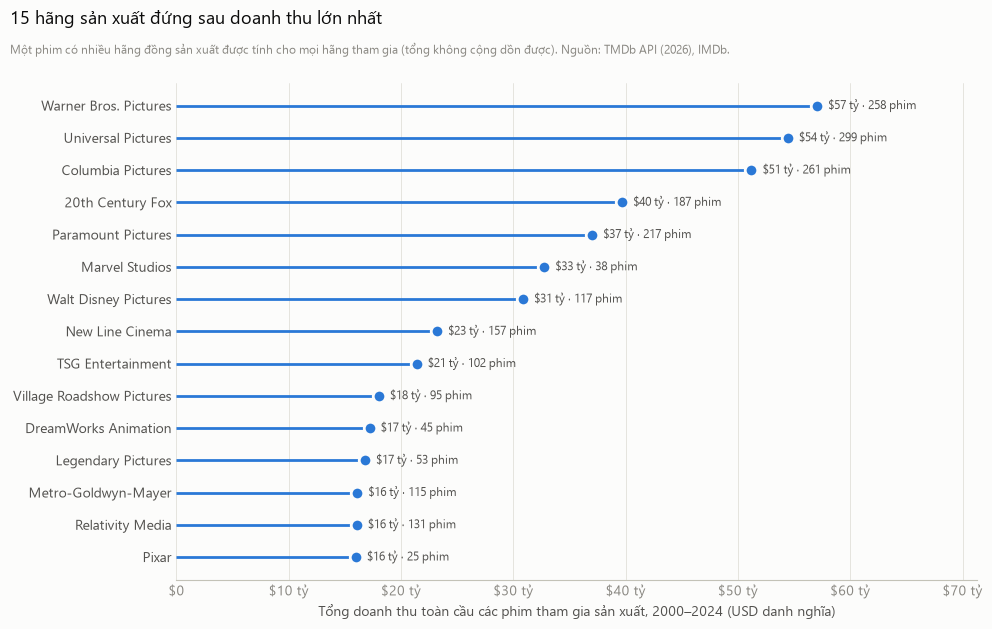

In [9]:
recent = fin[fin["release_date"].dt.year.between(2000, 2024)].dropna(subset=["production_companies"])
comp = recent.assign(company=recent["production_companies"].str.split(",")).explode("company")
agg = comp.groupby("company").agg(revenue=("revenue", "sum"), films=("imdb_id", "nunique")).nlargest(15, "revenue")[::-1]
fig, ax = plt.subplots(figsize=(10, 6.4))
V.style_axes(ax, grid="x")
y = np.arange(len(agg))
ax.hlines(y, 0, agg["revenue"], color=V.BLUE, linewidth=2)
ax.plot(agg["revenue"], y, "o", markersize=9, color=V.BLUE, markeredgecolor=V.SURFACE, markeredgewidth=2)
for yi, rev, n in zip(y, agg["revenue"], agg["films"]):
    ax.annotate(f"${rev / 1e9:.0f} tỷ · {n:,} phim", xy=(rev, yi), xytext=(8, 0), textcoords="offset points",
                va="center", color=V.INK2, fontsize=8.5)
ax.set_yticks(y)
ax.set_yticklabels(agg.index, color=V.INK2)
ax.xaxis.set_major_formatter(money)
ax.set_xlim(0, agg["revenue"].max() * 1.25)
ax.set_xlabel("Tổng doanh thu toàn cầu các phim tham gia sản xuất, 2000–2024 (USD danh nghĩa)")
V.titles(fig, "15 hãng sản xuất đứng sau doanh thu lớn nhất",
         f"Một phim có nhiều hãng đồng sản xuất được tính cho mọi hãng tham gia (tổng không cộng dồn được). {SRC}")
V.save(fig, FOLDER, "07_top_companies")

**Nhận xét.** Các "Big Five" Hollywood (Warner Bros., Universal, Columbia/Sony, Fox, Paramount) dẫn đầu về tổng doanh thu. **Marvel Studios** chỉ 38 phim nhưng đạt ~$33 tỷ — hiệu quả trên mỗi phim cao nhất; Pixar tương tự (25 phim, ~$16 tỷ). Lưu ý phim đồng sản xuất được tính cho mọi hãng, nên các cột không cộng lại được.

## Tóm tắt phần TMDb

| Khía cạnh | Phát hiện chính |
|---|---|
| Lợi nhuận | Chỉ ~1/3 phim vượt hòa vốn; trung vị mọi thể loại đều lỗ hoặc hòa |
| Thể loại | Hoạt hình, phiêu lưu sinh lời nhất; lịch sử, chiến tranh kém nhất |
| Lịch phát hành | Bom tấn dồn vào hè và cuối năm |
| Cửa sổ chiếu rạp | COVID rút từ ~76 xuống ~32 ngày và không quay lại |
| Địa lý | Mỹ ~38%, Ấn Độ ~10% (có thiên lệch nguồn) |
| Nhượng quyền | ~25% số phim nhưng tới ~70% doanh thu |